In [2]:
# upload dataset
import pandas as pd
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
dataset_path = '/content/drive/MyDrive/Colab/augmented.csv'

# Load the dataset
try:
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print(f"Error: The file '{dataset_path}' was not found. Please ensure it exists in your Google Drive.")
    df = None

if df is not None:
    # Display the first 5 rows of the DataFrame
    print("\nFirst 5 rows of the dataset:")
    display(df.head())
    # Display basic information about the DataFrame
    print("\nDataFrame Info:")
    df.info()

Mounted at /content/drive
Dataset loaded successfully.

First 5 rows of the dataset:


,user,gender,age,how_tall_in_meters,weight,body_mass_index,x1,y1,z1,x2,...,pitch2,yaw2,mag3,roll3,pitch3,yaw3,mag4,roll4,pitch4,yaw4
0,debora,Woman,46,1.62,75,28.6,-3,92,-63,-23,...,41.308515,141.952957,138.942434,131.496468,-2.062298,87.247515,233.918789,-144.981829,39.884957,-145.523912
1,debora,Woman,46,1.62,75,28.6,-3,94,-64,-21,...,39.521196,139.398705,138.246157,130.872408,5.812229,97.666804,232.469353,-144.350344,39.862300,-145.085476
2,debora,Woman,46,1.62,75,28.6,-1,97,-61,-12,...,25.641006,120.963757,138.148471,130.872408,5.399617,97.125016,233.137299,-144.162347,40.367439,-145.443194
3,debora,Woman,46,1.62,75,28.6,-2,96,-57,-15,...,29.603745,125.537678,137.499091,130.555894,5.425194,97.125016,232.770273,-144.044667,41.094312,-146.051457
4,debora,Woman,46,1.62,75,28.6,-1,96,-61,-13,...,27.474432,123.023868,137.499091,130.555894,5.425194,97.125016,233.824721,-143.972627,40.869343,-145.794542



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165633 entries, 0 to 165632
Data columns (total 35 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   user                165633 non-null  object 
 1   gender              165633 non-null  object 
 2   age                 165633 non-null  int64  
 3   how_tall_in_meters  165633 non-null  float64
 4   weight              165633 non-null  int64  
 5   body_mass_index     165633 non-null  float64
 6   x1                  165633 non-null  int64  
 7   y1                  165633 non-null  int64  
 8   z1                  165633 non-null  int64  
 9   x2                  165633 non-null  int64  
 10  y2                  165633 non-null  int64  
 11  z2                  165633 non-null  int64  
 12  x3                  165633 non-null  int64  
 13  y3                  165633 non-null  int64  
 14  z3                  165633 non-null  int64  
 15  x4               

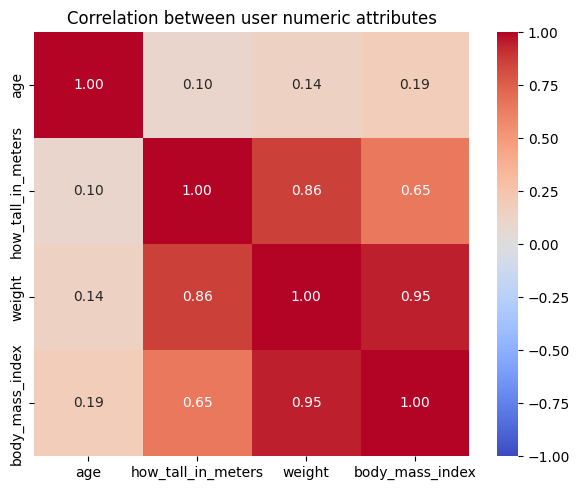

In [3]:
# Correlation heatmap for numeric user attributes
numeric_user_cols = ['age', 'how_tall_in_meters', 'weight', 'body_mass_index']
corr_user = df[numeric_user_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr_user, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between user numeric attributes')
plt.tight_layout()
plt.show()

Accelerometer columns present: ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']


,count,mean,std,min,25%,50%,75%,max
x1,165633.0,-6.649327,11.616238,-306.0,-12.0,-6.0,0.0,509.0
y1,165633.0,88.293667,23.895829,-271.0,78.0,94.0,101.0,533.0
z1,165633.0,-93.164611,39.409423,-603.0,-120.0,-98.0,-64.0,411.0
x2,165633.0,-87.827504,169.435194,-494.0,-35.0,-9.0,4.0,473.0
y2,165633.0,-52.065047,205.159763,-517.0,-29.0,27.0,86.0,295.0
z2,165633.0,-175.055200,192.816615,-617.0,-141.0,-118.0,-29.0,122.0
x3,165633.0,17.423515,52.635388,-499.0,9.0,22.0,34.0,507.0
y3,165633.0,104.517167,54.155843,-506.0,95.0,107.0,120.0,517.0
z3,165633.0,-93.881726,45.389646,-613.0,-103.0,-90.0,-80.0,410.0
x4,165633.0,-167.641448,38.311342,-702.0,-190.0,-168.0,-153.0,-13.0


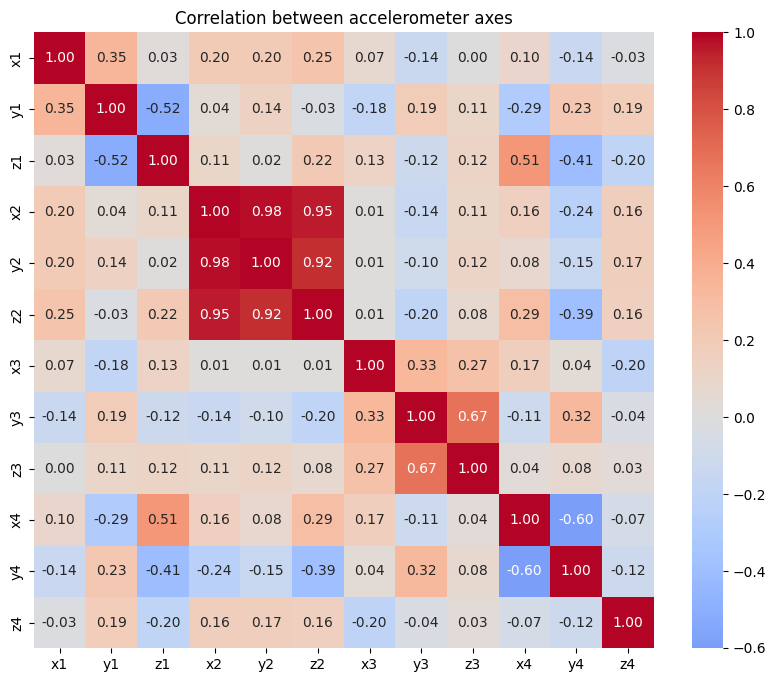

In [4]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display

# Define expected accelerometer columns and keep only those present in the dataframe
accel_cols = ['x1','y1','z1','x2','y2','z2','x3','y3','z3','x4','y4','z4']
present_cols = [c for c in accel_cols if c in df.columns]
print('Accelerometer columns present:', present_cols)

if len(present_cols) == 0:
    print('No accelerometer columns found in the dataframe. Skipping accelerometer analysis.')
else:
    # Summary statistics for present columns
    display(df[present_cols].describe().T)

    # Correlation heatmap between axes
    corr = df[present_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
    plt.title('Correlation between accelerometer axes')
    plt.show()

### Correlation Heatmap for Accelerometer Data by Class


Generating heatmap for class: sitting


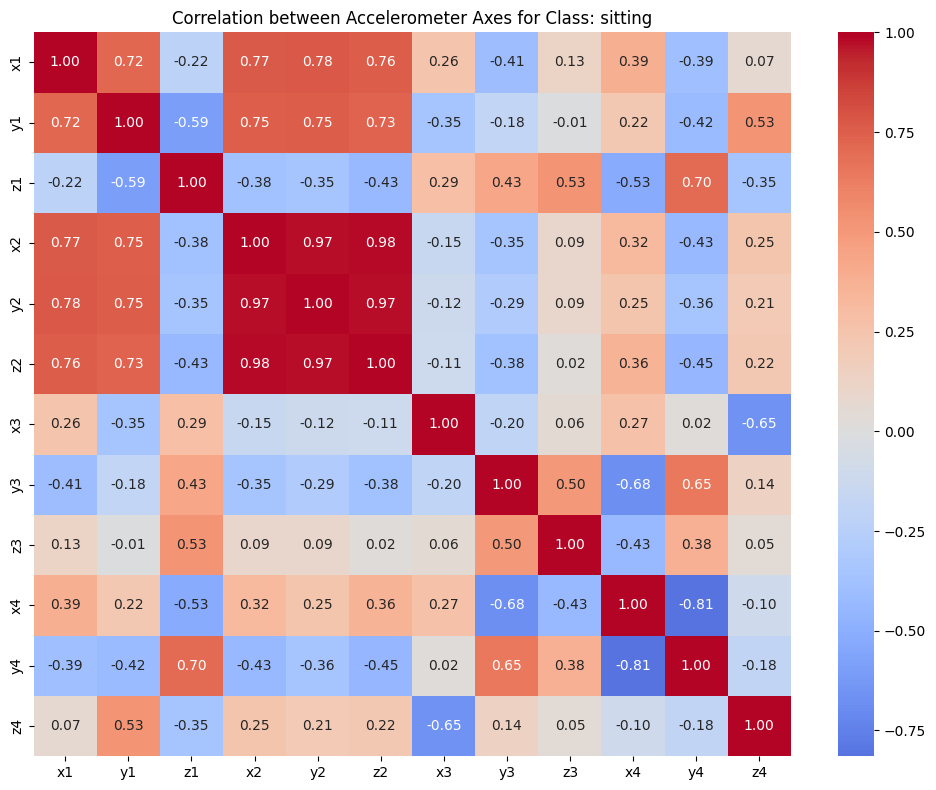


Generating heatmap for class: sittingdown


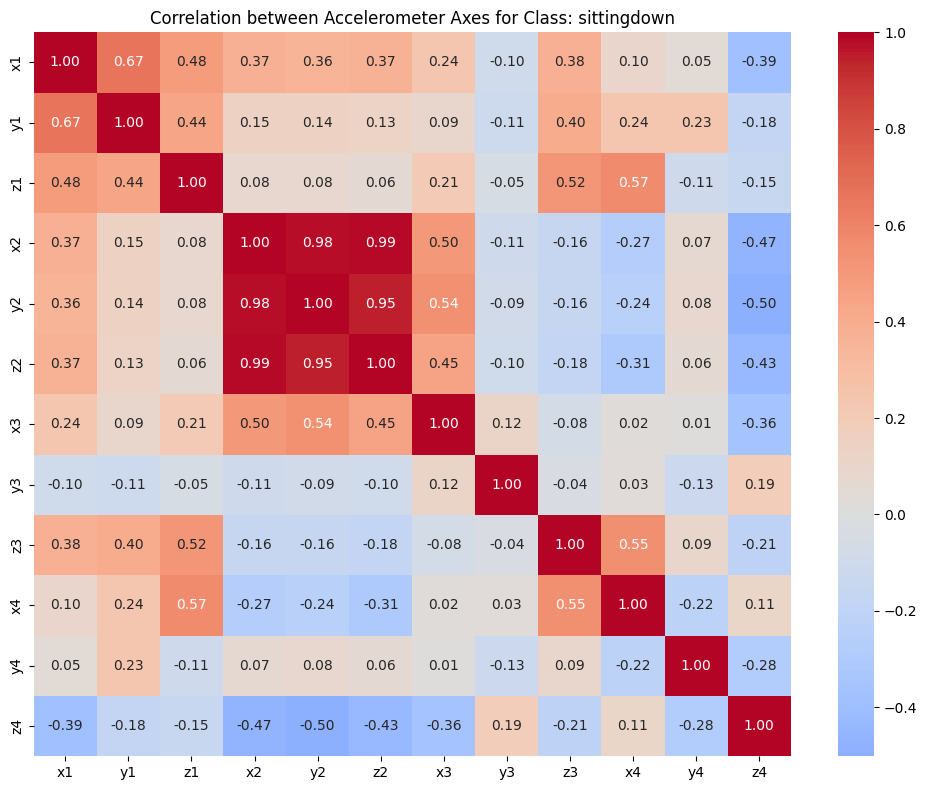


Generating heatmap for class: standing


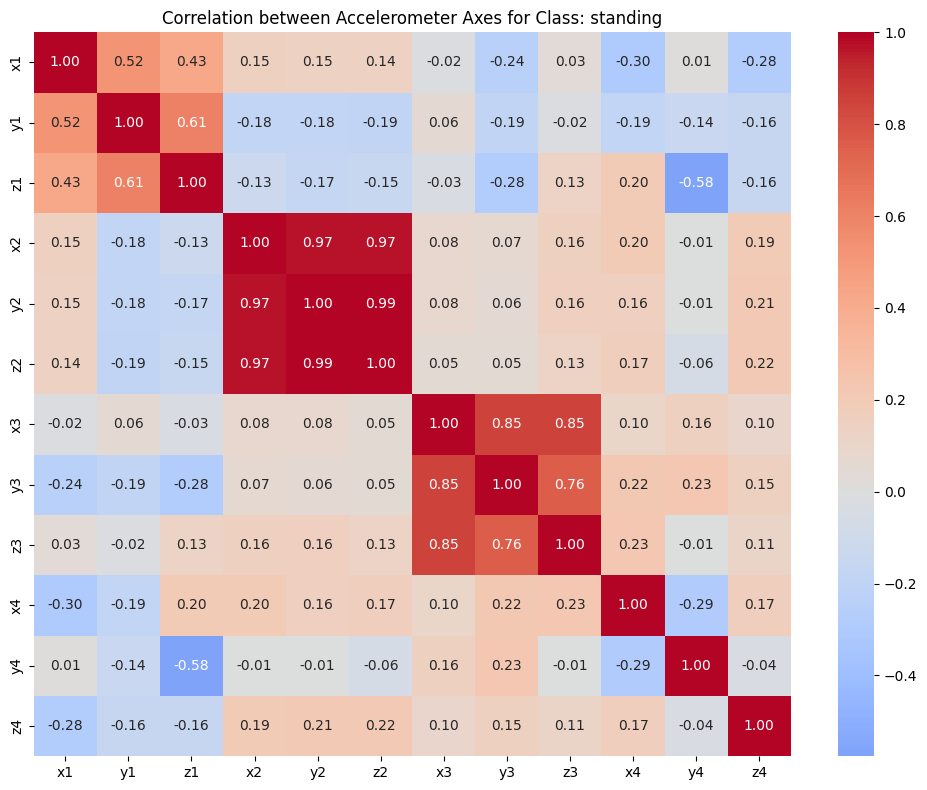


Generating heatmap for class: standingup


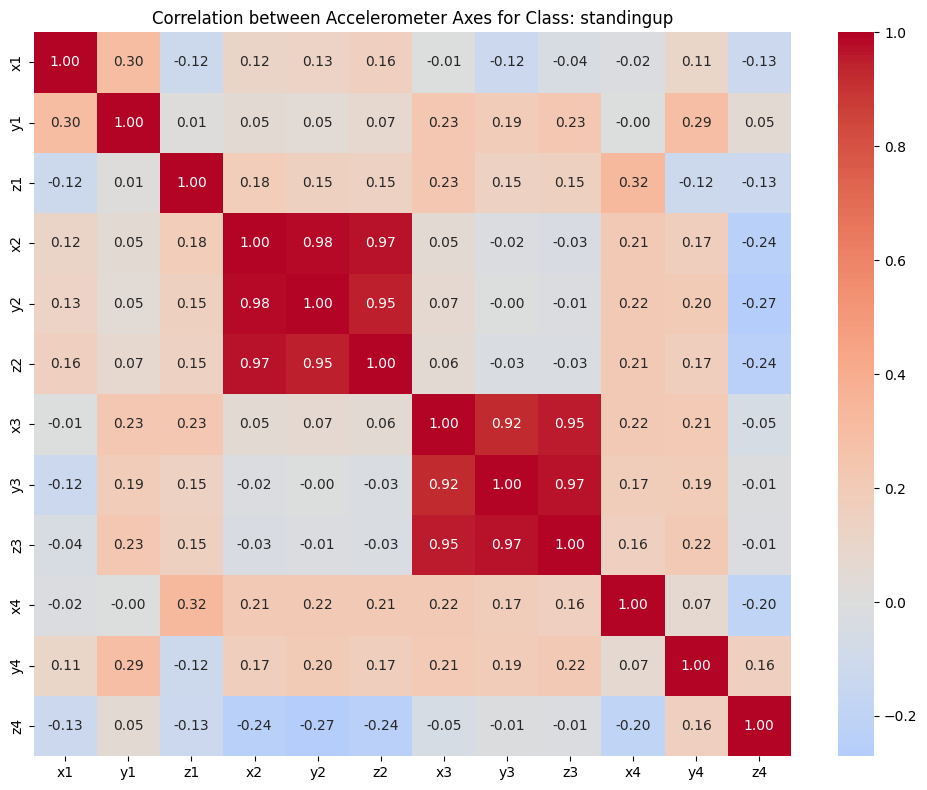


Generating heatmap for class: walking


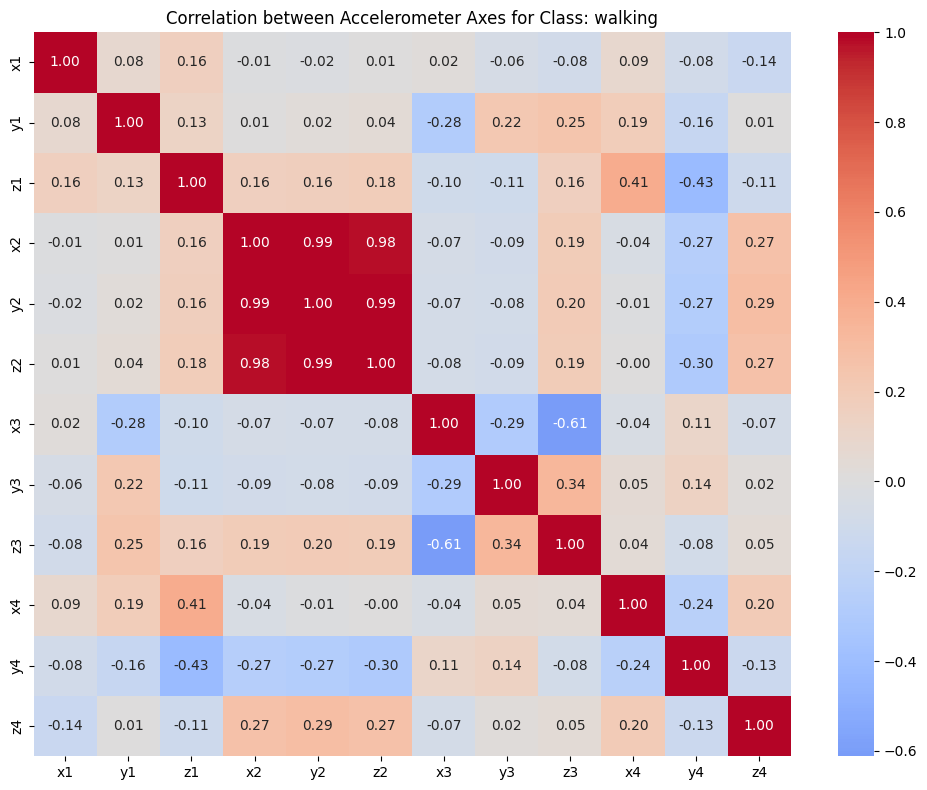

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get unique classes
unique_classes = df['class'].unique()

# Loop through each unique class and generate a heatmap
for cls in unique_classes:
    print(f"\nGenerating heatmap for class: {cls}")
    # Filter the DataFrame for the current class
    df_class = df[df['class'] == cls]

    # Select only the accelerometer columns that are present
    accel_cols_class = [col for col in present_cols if col in df_class.columns]

    if len(accel_cols_class) > 1:
        # Calculate the correlation matrix for the accelerometer data of the current class
        corr_class = df_class[accel_cols_class].corr()

        # Create the heatmap
        plt.figure(figsize=(10, 8))
        sns.heatmap(corr_class, annot=True, fmt='.2f', cmap='coolwarm', center=0)
        plt.title(f'Correlation between Accelerometer Axes for Class: {cls}')
        plt.tight_layout()
        plt.show()
    else:
        print(f"Not enough accelerometer columns to compute correlation for class: {cls}")